In [33]:
import pandas as pd
import numpy as np

df = pd.read_csv("Admission_Predict.csv")
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65


In [34]:
df["Admit"] = np.where(
    df["Chance of Admit"] > 0.87,
    1,
    0
)
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92,1
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76,0
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72,0
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80,0
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65,0


In [35]:
df = df.drop("Serial No.", axis=1)
df = df.drop("Chance of Admit", axis=1)
df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admit
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0


In [36]:
df.isna().sum()

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             3
Admit                0
dtype: int64

In [37]:
df["Research"] = df["Research"].fillna(df["Research"].mode())
df.isna().sum()

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             3
Admit                0
dtype: int64

In [38]:
X = df.drop("Admit", axis=1)
y = df["Admit"]

In [39]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
from sklearn import tree

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=15
)

In [41]:
tree_ent = DecisionTreeClassifier(criterion='entropy')
tree_ent.fit(X_test, y_test)
y_test_pred_ent = tree_ent.predict(X_test)
y_train_pred_ent = tree_ent.predict(X_train)

tree_gini = DecisionTreeClassifier(criterion='gini')
tree_gini.fit(X_test, y_test)
y_test_pred_gini = tree_gini.predict(X_test)
y_train_pred_gini = tree_gini.predict(X_train)

In [42]:
print("Entropy Train Data\n")
print("Confusion matrix:\n", confusion_matrix(y_train, y_train_pred_ent))
print("Accuracy: ", accuracy_score(y_train, y_train_pred_ent))
print("Precision: ", precision_score(y_train, y_train_pred_ent))
print("Recall: ", recall_score(y_train, y_train_pred_ent))

Entropy Train Data

Confusion matrix:
 [[258   6]
 [  8  48]]
Accuracy:  0.95625
Precision:  0.8888888888888888
Recall:  0.8571428571428571


In [43]:
print("Entropy Test Data\n")
print("Confusion matrix:\n", confusion_matrix(y_test, y_test_pred_ent))
print("Accuracy: ", accuracy_score(y_test, y_test_pred_ent))
print("Precision: ", precision_score(y_test, y_test_pred_ent))
print("Recall: ", recall_score(y_test, y_test_pred_ent))

Entropy Test Data

Confusion matrix:
 [[66  0]
 [ 0 14]]
Accuracy:  1.0
Precision:  1.0
Recall:  1.0


[Text(0.5, 0.875, 'x[5] <= 9.19\nentropy = 0.669\nsamples = 80\nvalue = [66, 14]'),
 Text(0.25, 0.625, 'x[0] <= 326.5\nentropy = 0.113\nsamples = 66\nvalue = [65, 1]'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'entropy = 0.0\nsamples = 62\nvalue = [62, 0]'),
 Text(0.375, 0.375, 'x[4] <= 4.25\nentropy = 0.811\nsamples = 4\nvalue = [3, 1]'),
 Text(0.25, 0.125, 'entropy = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.5, 0.125, 'entropy = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.75, 0.625, 'x[2] <= 3.5\nentropy = 0.371\nsamples = 14\nvalue = [1, 13]'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'entropy = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.875, 0.375, 'entropy = 0.0\nsamples = 13\nvalue = [0, 13]')]

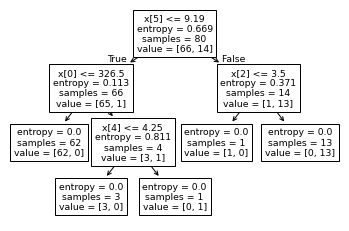

In [44]:
tree.plot_tree(tree_ent)

In [45]:
print("Gini Train Data\n")
print("Confusion matrix:\n", confusion_matrix(y_train, y_train_pred_gini))
print("Accuracy: ", accuracy_score(y_train, y_train_pred_gini))
print("Precision: ", precision_score(y_train, y_train_pred_gini))
print("Recall: ", recall_score(y_train, y_train_pred_gini))

Gini Train Data

Confusion matrix:
 [[258   6]
 [  8  48]]
Accuracy:  0.95625
Precision:  0.8888888888888888
Recall:  0.8571428571428571


In [46]:
print("Gini Test Data\n")
print("Confusion matrix:\n", confusion_matrix(y_test, y_test_pred_gini))
print("Accuracy: ", accuracy_score(y_test, y_test_pred_gini))
print("Precision: ", precision_score(y_test, y_test_pred_gini))
print("Recall: ", recall_score(y_test, y_test_pred_gini))

Gini Test Data

Confusion matrix:
 [[66  0]
 [ 0 14]]
Accuracy:  1.0
Precision:  1.0
Recall:  1.0


[Text(0.5, 0.875, 'x[5] <= 9.19\ngini = 0.289\nsamples = 80\nvalue = [66, 14]'),
 Text(0.25, 0.625, 'x[0] <= 326.5\ngini = 0.03\nsamples = 66\nvalue = [65, 1]'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'gini = 0.0\nsamples = 62\nvalue = [62, 0]'),
 Text(0.375, 0.375, 'x[4] <= 4.25\ngini = 0.375\nsamples = 4\nvalue = [3, 1]'),
 Text(0.25, 0.125, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.5, 0.125, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.75, 0.625, 'x[2] <= 3.5\ngini = 0.133\nsamples = 14\nvalue = [1, 13]'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.875, 0.375, 'gini = 0.0\nsamples = 13\nvalue = [0, 13]')]

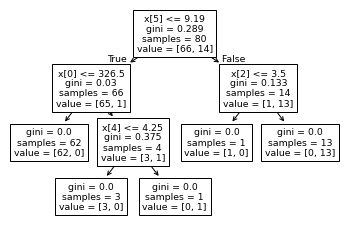

In [47]:
tree.plot_tree(tree_gini)

In [ ]:
gre = int(input("Enter GRE score: "))
toefl = int(input("Enter TOEFL score: "))
rating = int(input("Enter University Rating: "))
sop = float(input("Enter SOP: "))
lor = float(input("Enter LOR: "))
cgpa = float(input("Enter CGPA: "))
research = int(input("Research experience (Yes = 1 / No = 0): "))

user_data = pd.DataFrame({
    "GRE Score": [gre],
    "TOEFL Score": [toefl],
    "University Rating": [rating],
    "SOP": [sop],
    "LOR": [lor],
    "CGPA": [cgpa],
    "Research": [research]
})

ent_prediction = tree_ent.predict(user_data)[0]

Enter GRE score: 754
Enter TOEFL score: 104
Enter University Rating: 4


In [ ]:
print("--- Decision Tree Admission Prediction Results ---")
if ent_prediction == 1:
    print("Prediction: The student is likely to be ADMITTED!")
else:
    print("Prediction: The student is UNLIKELY to be admitted.")

In [ ]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

y_train_pred_nb = nb_model.predict(X_train)
y_test_pred_nb = nb_model.predict(X_test)

In [ ]:
print("Naive Bayes Train Data\n")
print("Confusion matrix:\n", confusion_matrix(y_train, y_train_pred_nb))
print("Accuracy: ", accuracy_score(y_train, y_train_pred_nb))
print("Precision: ", precision_score(y_train, y_train_pred_nb))
print("Recall: ", recall_score(y_train, y_train_pred_nb))

print("Naive Bayes Test Data\n")
print("Confusion matrix:\n", confusion_matrix(y_test, y_test_pred_nb))
print("Accuracy: ", accuracy_score(y_test, y_test_pred_nb))
print("Precision: ", precision_score(y_test, y_test_pred_nb))
print("Recall: ", recall_score(y_test, y_test_pred_nb))

In [ ]:
nb_prediction = nb_model.predict(user_data)[0]

print("--- Naive Bayes Admission Prediction Results ---")
if nb_prediction == 1:
    print("Prediction: The student is likely to be ADMITTED!")
else:
    print("Prediction: The student is UNLIKELY to be admitted.")